# Praktikum Pertemuan 1 — Akuisisi dan Representasi Citra Digital

**Notebook Pengajaran (Demo di Kelas)**

**Mata Kuliah:** CII3B4 Visi Komputer · **Durasi:** 100 menit · **Sifat:** Individu
**Sub-CLO:** Sub-CLO-12-1-1 — Mahasiswa mampu menjelaskan konsep dasar sistem pengenalan objek visual

> Notebook ini menjembatani objek nyata, sensor kamera, dan array NumPy. Jalankan sel secara berurutan karena setiap langkah menggunakan hasil langkah sebelumnya.

## Peta Kegiatan dan Alokasi Waktu

| Bagian | Aktivitas | Waktu |
|---|---|---:|
| Konsep | Mengikuti rantai akuisisi, sampling, kuantisasi, dan representasi array | 15 menit |
| Demo 1–3 | Membaca citra, memeriksa piksel/memori, dan memisahkan kanal | 30 menit |
| Demo 4–6 | ROI, perubahan resolusi, dan kompresi JPEG | 35 menit |
| Eksperimen | Menerapkan langkah pada foto sendiri | 15 menit |
| Refleksi | Menjawab cek pemahaman dan merangkum temuan | 5 menit |

**Alur besar:** dunia nyata → cahaya → sensor → sampling dan kuantisasi → matriks angka → operasi komputer.

## 1. Tujuan Praktikum

Setelah praktikum, mahasiswa mampu:

1. Menjelaskan bagaimana kamera mengubah cahaya menjadi citra digital melalui sampling spasial dan kuantisasi intensitas.
2. Membaca citra dari berkas dan mengidentifikasi `shape`, `dtype`, jumlah elemen, rentang nilai, serta penggunaan memorinya.
3. Menjelaskan perbedaan urutan kanal BGR dan RGB serta memvisualisasikan tiap kanal secara tepat.
4. Menghubungkan koordinat `(x, y)` dengan indeks array `[baris, kolom]` ketika memotong ROI.
5. Mengukur informasi yang hilang akibat penurunan resolusi dan kompresi JPEG.
6. Menyimpulkan perbedaan ukuran citra mentah di memori dan ukuran berkas terkompresi di media penyimpanan.

## 2. Alat dan Bahan

- Python 3.10 atau lebih baru.
- `opencv-python` ≥ 4.8, `numpy` ≥ 1.24, `scikit-image` ≥ 0.21, dan `matplotlib` ≥ 3.7.
- Citra utama: `skimage.data.astronaut()` berukuran 512×512×3; tidak perlu unduhan.
- Citra tambahan: **satu foto sendiri** dari ponsel, misalnya papan nama atau objek di kampus, disimpan sebagai `foto_saya.jpg`.
- Folder `hasil/` dibuat otomatis oleh notebook.

> Citra bawaan digunakan agar hasil demo pengajar dapat direproduksi. Foto sendiri dipakai untuk menguji apakah pemahaman tetap berlaku pada data nyata.

In [1]:
# Jalankan hanya bila paket belum tersedia, lalu restart kernel bila diminta.
# %pip install opencv-python numpy scikit-image matplotlib

## 3. Dasar Teori

### 3.1 Dari cahaya menjadi matriks angka

Akuisisi citra dimulai ketika cahaya dari objek masuk melalui lensa dan mengenai sensor. Sensor terdiri atas elemen peka cahaya. Setiap elemen mengubah energi cahaya menjadi sinyal listrik, lalu konverter analog-ke-digital mengubah sinyal tersebut menjadi angka.

Dua proses diskretisasi terjadi:

- **Sampling spasial** menentukan berapa banyak lokasi yang diukur. Hasilnya adalah banyaknya piksel sepanjang tinggi dan lebar. Resolusi 512×512 berarti ada 262.144 lokasi piksel.
- **Kuantisasi intensitas** menentukan berapa banyak tingkat nilai yang tersedia. Pada citra 8-bit, setiap kanal mempunyai `2^8 = 256` tingkat, yaitu 0–255.

Semakin rapat sampling, semakin halus detail spasial yang dapat direkam. Semakin banyak bit kuantisasi, semakin halus perubahan intensitas yang dapat dibedakan. Keduanya tidak menjamin kualitas tanpa batas: lensa buram, sensor bising, pencahayaan buruk, atau kompresi tetap dapat menghilangkan informasi.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from pathlib import Path
from skimage import data

HASIL = Path("hasil")
HASIL.mkdir(exist_ok=True)

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
MUTED = "#52514e"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREEN = "#008300"
RED = "#e34948"
GRID = "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": INK,
    "font.size": 10,
})
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.13.0 | NumPy 2.4.4


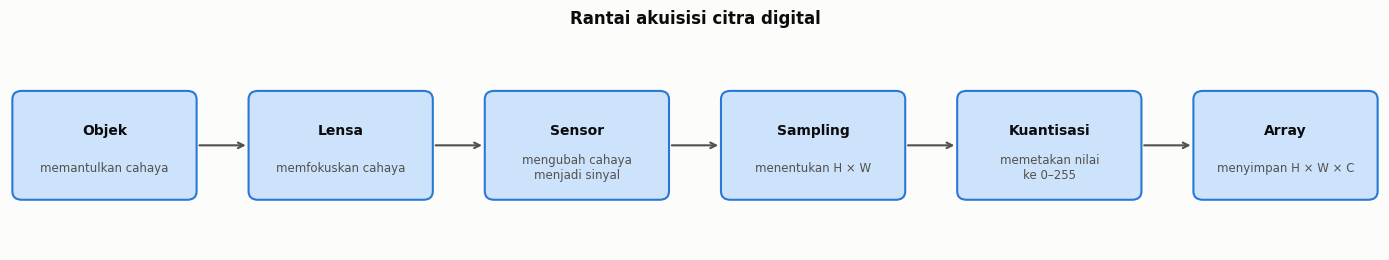

In [3]:
tahap = [
    ("Objek", "memantulkan cahaya"),
    ("Lensa", "memfokuskan cahaya"),
    ("Sensor", "mengubah cahaya\nmenjadi sinyal"),
    ("Sampling", "menentukan H × W"),
    ("Kuantisasi", "memetakan nilai\nke 0–255"),
    ("Array", "menyimpan H × W × C"),
]

fig, ax = plt.subplots(figsize=(14, 2.7))
ax.set_xlim(-0.4, len(tahap) - 0.6)
ax.set_ylim(0, 1)
ax.axis("off")
for i, (judul, keterangan) in enumerate(tahap):
    ax.add_patch(FancyBboxPatch(
        (i - 0.36, 0.27), 0.72, 0.46,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor="#cde2fb", edgecolor=BLUE, linewidth=1.5,
    ))
    ax.text(i, 0.57, judul, ha="center", va="center", weight="bold")
    ax.text(i, 0.39, keterangan, ha="center", va="center", fontsize=8.5, color=MUTED)
    if i < len(tahap) - 1:
        ax.annotate("", xy=(i + 0.61, 0.5), xytext=(i + 0.39, 0.5),
                    arrowprops={"arrowstyle": "->", "color": MUTED, "lw": 1.5})
ax.set_title("Rantai akuisisi citra digital", pad=12, weight="bold")
fig.tight_layout()
fig.savefig(HASIL / "00_rantai_akuisisi.png", dpi=140, bbox_inches="tight")
plt.show()

**Cara membaca diagram:** bagian kiri masih berupa fenomena fisik; mulai dari sampling dan kuantisasi, informasi diubah menjadi data diskret. Komputer tidak “melihat astronaut”, melainkan mengolah kumpulan angka yang posisi dan nilainya mempunyai arti.

**Pertanyaan cepat:** jika ukuran sensor tetap tetapi jumlah sampel dinaikkan, aspek kualitas apa yang berubah? Apakah jumlah tingkat intensitas otomatis ikut berubah?

### 3.2 Representasi citra sebagai array

Citra abu-abu biasanya berbentuk `(tinggi, lebar)`. Citra berwarna berbentuk `(tinggi, lebar, kanal)`. Untuk citra 8-bit tiga kanal:

```text
jumlah_elemen = tinggi × lebar × kanal
ukuran_memori = jumlah_elemen × 1 byte
```

OpenCV menyimpan warna dalam urutan **BGR**, sedangkan Matplotlib dan banyak pustaka lain mengharapkan **RGB**. Nilai piksel `[46, 16, 31]` pada OpenCV berarti biru 46, hijau 16, merah 31. Jika array BGR langsung diberikan ke Matplotlib, kanal merah dan biru tertukar sehingga warna tampak salah.

`uint8` hanya menyimpan bilangan bulat 0–255. Operasi aritmetika yang melampaui rentang itu dapat meluber (*overflow*), sehingga perhitungan selisih atau penjumlahan sebaiknya dilakukan setelah konversi ke `int16` atau `float32`.

### 3.3 Memori, berkas, dan kompresi

`img.nbytes` adalah ruang yang dipakai array saat berada di memori. Ukuran berkas di disk dapat jauh lebih kecil karena encoder menyimpan pola secara ringkas:

- **PNG** bersifat *lossless*: setelah didekode, nilai piksel kembali sama.
- **JPEG** bersifat *lossy*: ukuran lebih kecil diperoleh dengan membuang sebagian informasi visual.

Begitu PNG atau JPEG dibaca, citra kembali menjadi array penuh. Karena itu, berkas JPEG 100 KB dapat berubah menjadi array 786.432 byte saat diproses.

### 3.4 Koordinat, ROI, dan perubahan ukuran

Titik asal citra berada di kiri atas. Sumbu `x` bergerak ke kanan dan `y` bergerak ke bawah, tetapi NumPy mengindeks array sebagai `[baris, kolom]` atau `[y, x]`. Kotak detektor `(x, y, w, h)` harus dipotong dengan:

```python
roi = img[y:y+h, x:x+w]
```

Potongan NumPy biasanya merupakan *view* yang berbagi memori dengan array asal. Gunakan `.copy()` bila ROI akan diubah secara mandiri.

`cv2.resize` menerima ukuran dalam urutan `(lebar, tinggi)`. Ketika citra dikecilkan, banyak piksel digabung. Membesarkannya kembali hanya membuat piksel baru dari informasi yang tersisa; detail asli tidak dapat diciptakan kembali.

## 4. Langkah Praktikum

### Langkah 1 — Membuat citra uji dan membacanya kembali

Citra dari `skimage` sudah berurutan RGB. Kita mengubahnya ke BGR sebelum menyimpan dengan OpenCV, lalu membaca kembali berkas tersebut seperti data kamera biasa.

In [5]:
rgb_sumber = data.astronaut()                         # RGB, uint8
bgr_sumber = cv2.cvtColor(rgb_sumber, cv2.COLOR_RGB2BGR)
nama_png = Path("citra_uji.png")
if not cv2.imwrite(str(nama_png), bgr_sumber):
    raise OSError(f"Gagal menyimpan {nama_png}")

img = cv2.imread(str(nama_png), cv2.IMREAD_COLOR)
if img is None:
    raise FileNotFoundError(f"OpenCV gagal membaca {nama_png.resolve()}")

rgb_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
png_bytes = nama_png.stat().st_size
# print("lokasi       :", nama_png.resolve())
print("ukuran berkas:", f"{png_bytes:,}", "byte")
print("shape        :", img.shape)
print("dtype / ndim :", img.dtype, "/", img.ndim)

ukuran berkas: 464,915 byte
shape        : (512, 512, 3)
dtype / ndim : uint8 / 3


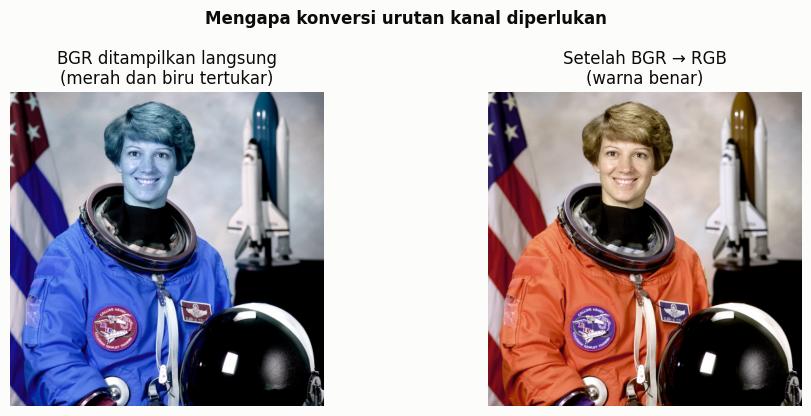

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
ax[0].imshow(img)  # sengaja salah: BGR diperlakukan sebagai RGB
ax[0].set_title("BGR ditampilkan langsung\n(merah dan biru tertukar)")
ax[1].imshow(rgb_img)
ax[1].set_title("Setelah BGR → RGB\n(warna benar)")
for a in ax:
    a.axis("off")
fig.suptitle("Mengapa konversi urutan kanal diperlukan", weight="bold")
fig.tight_layout()
fig.savefig(HASIL / "01_bgr_vs_rgb.png", dpi=140, bbox_inches="tight")
plt.show()

**Yang harus diamati:** kedua panel berasal dari angka yang sama; hanya interpretasi posisi kanal yang berubah. Warna salah bukan berarti berkas rusak.

**Pertanyaan cepat:** jika `cv2.imread` menghasilkan `None`, dua penyebab umum adalah jalur/nama berkas salah dan berkas tidak dapat dibaca. Mengapa memeriksa `img is None` harus dilakukan sebelum mengakses `img.shape`?

### Langkah 2 — Membaca struktur, piksel, dan kebutuhan memori

Kita akan menghubungkan satu piksel pada posisi `(x=50, y=100)` dengan indeks NumPy `[100, 50]`, lalu membandingkan ukuran array mentah dan berkas PNG.

tinggi × lebar × kanal : 512 × 512 × 3
jumlah elemen          : 786,432
memori array           : 786,432 byte = 0.75 MiB
ukuran berkas PNG      : 464,915 byte
rasio mentah : PNG     : 1.69 : 1
piksel [y=100, x=50] BGR: [46 16 31] | RGB: [31 16 46]
min / maks / rata-rata : 0 / 255 / 114.60


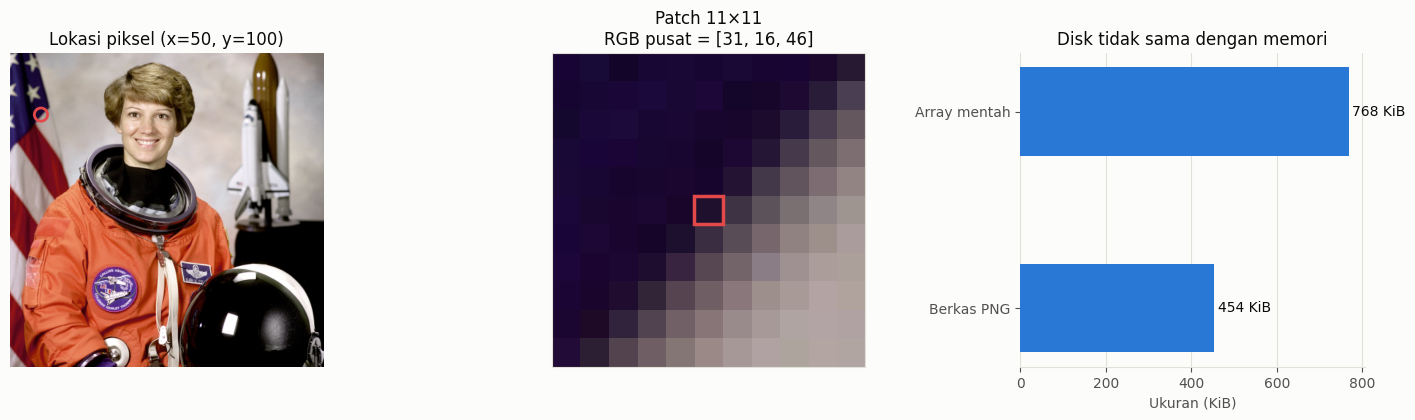

In [6]:
h, w, c = img.shape
jumlah_elemen = h * w * c
x_piksel, y_piksel = 50, 100
bgr_piksel = img[y_piksel, x_piksel]
rgb_piksel = rgb_img[y_piksel, x_piksel]

print(f"tinggi × lebar × kanal : {h} × {w} × {c}")
print("jumlah elemen          :", f"{jumlah_elemen:,}")
print("memori array           :", f"{img.nbytes:,}", "byte =", f"{img.nbytes / 2**20:.2f}", "MiB")
print("ukuran berkas PNG      :", f"{png_bytes:,}", "byte")
print("rasio mentah : PNG     :", f"{img.nbytes / png_bytes:.2f} : 1")
print(f"piksel [y={y_piksel}, x={x_piksel}] BGR:", bgr_piksel, "| RGB:", rgb_piksel)
print("min / maks / rata-rata :", img.min(), "/", img.max(), "/", f"{img.mean():.2f}")

r = 5
patch = rgb_img[y_piksel-r:y_piksel+r+1, x_piksel-r:x_piksel+r+1]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.2, 1, 0.9]})
ax[0].imshow(rgb_img)
ax[0].scatter([x_piksel], [y_piksel], s=90, facecolors="none", edgecolors=RED, linewidths=2)
ax[0].set_title(f"Lokasi piksel (x={x_piksel}, y={y_piksel})")
ax[0].axis("off")

ax[1].imshow(patch, interpolation="nearest")
ax[1].add_patch(Rectangle((r-0.5, r-0.5), 1, 1, fill=False, edgecolor=RED, linewidth=2.5))
ax[1].set_title(f"Patch 11×11\nRGB pusat = {rgb_piksel.tolist()}")
ax[1].set_xticks([]); ax[1].set_yticks([])

nilai_kib = [png_bytes / 1024, img.nbytes / 1024]
bars = ax[2].barh(["Berkas PNG", "Array mentah"], nilai_kib, color=BLUE, height=0.45)
ax[2].set_xlabel("Ukuran (KiB)")
ax[2].set_title("Disk tidak sama dengan memori")
ax[2].grid(axis="x", color=GRID, linewidth=0.8)
ax[2].set_axisbelow(True)
for bar, nilai in zip(bars, nilai_kib):
    ax[2].text(bar.get_width() + 8, bar.get_y() + bar.get_height()/2,
               f"{nilai:.0f} KiB", va="center", color=INK)
ax[2].spines[["top", "right", "left"]].set_visible(False)
fig.tight_layout()
fig.savefig(HASIL / "02_piksel_dan_memori.png", dpi=140, bbox_inches="tight")
plt.show()

**Interpretasi:** `img.size` dan `h × w × c` sama-sama menghitung 786.432 elemen. Karena `dtype` adalah `uint8` dan setiap elemen memakai satu byte, `img.nbytes` juga 786.432 byte. Ukuran PNG lebih kecil karena pola antarpiksel dikompresi tanpa mengubah isi setelah didekode.

**Pertanyaan cepat:** bila citra yang sama disimpan sebagai `float32`, berapa kali lebih besar kebutuhan memorinya? Jawaban tidak bergantung pada isi citra, melainkan pada jumlah byte per elemen.

### Langkah 3 — Memisahkan dan memvisualisasikan kanal warna

Satu kanal adalah matriks intensitas 2D. Saat kanal merah ditampilkan dengan colormap abu-abu, area yang banyak merah terlihat terang. Untuk melihat kontribusi warnanya, kanal tersebut harus ditempatkan kembali pada posisi R dari array RGB sementara dua kanal lain dibuat nol.

In [7]:
B, G, R = cv2.split(img)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
kanal_data = [("Biru", B), ("Hijau", G), ("Merah", R)]

for nama, kanal in kanal_data:
    print(f"{nama:6s}: shape={kanal.shape}, min={kanal.min():3d}, "
          f"maks={kanal.max():3d}, rata-rata={kanal.mean():6.2f}")
    cv2.imwrite(str(HASIL / f"kanal_{nama.lower()}.png"), kanal)
print("Abu-abu:", gray.shape, "|", f"{gray.nbytes:,}", "byte")

nol = np.zeros_like(B)
warna_biru = np.dstack([nol, nol, B])
warna_hijau = np.dstack([nol, G, nol])
warna_merah = np.dstack([R, nol, nol])

Biru  : shape=(512, 512), min=  0, maks=255, rata-rata= 96.48
Hijau : shape=(512, 512), min=  0, maks=255, rata-rata=105.76
Merah : shape=(512, 512), min=  0, maks=255, rata-rata=141.56
Abu-abu: (512, 512) | 262,144 byte


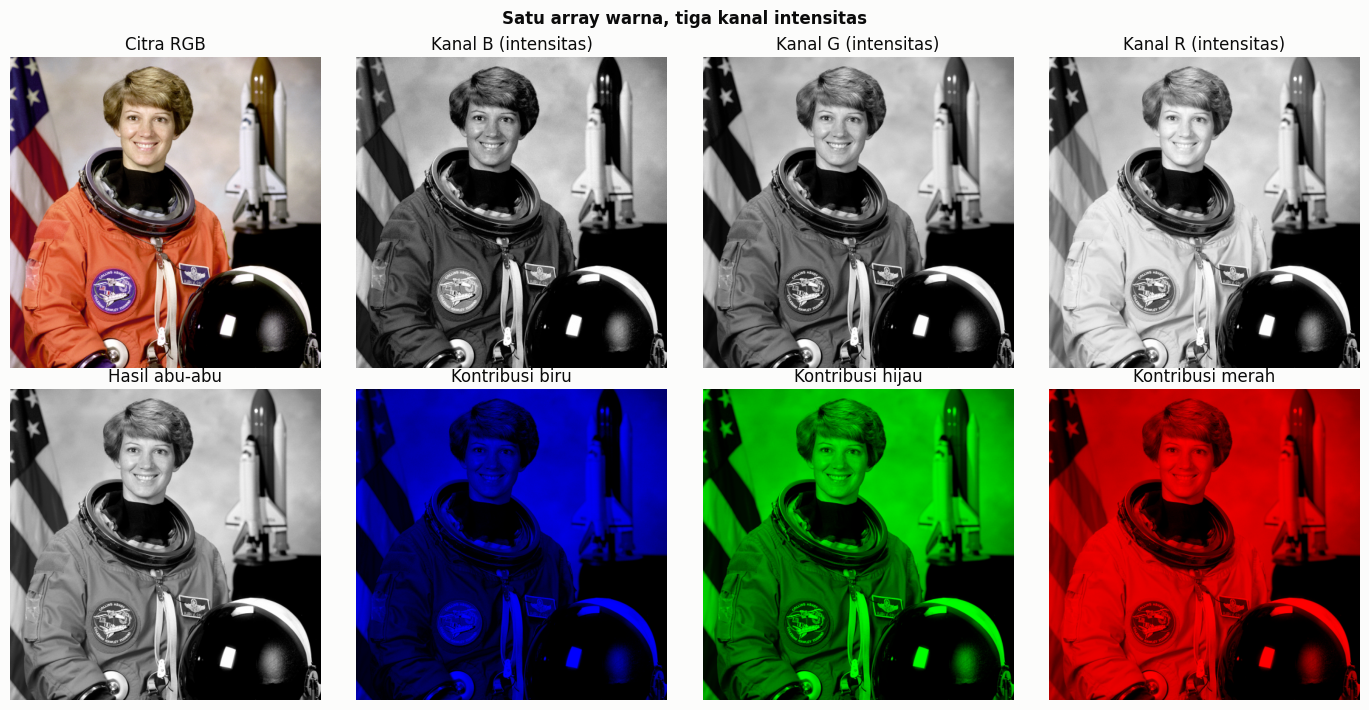

In [8]:
fig, ax = plt.subplots(2, 4, figsize=(14, 7.2))
panel = [
    (rgb_img, "Citra RGB", None),
    (B, "Kanal B (intensitas)", "gray"),
    (G, "Kanal G (intensitas)", "gray"),
    (R, "Kanal R (intensitas)", "gray"),
    (gray, "Hasil abu-abu", "gray"),
    (warna_biru, "Kontribusi biru", None),
    (warna_hijau, "Kontribusi hijau", None),
    (warna_merah, "Kontribusi merah", None),
]
for a, (gambar, judul, cmap) in zip(ax.ravel(), panel):
    a.imshow(gambar, cmap=cmap, vmin=0 if cmap else None, vmax=255 if cmap else None)
    a.set_title(judul)
    a.axis("off")
fig.suptitle("Satu array warna, tiga kanal intensitas", weight="bold")
fig.tight_layout()
fig.savefig(HASIL / "03_visual_kanal.png", dpi=140, bbox_inches="tight")
plt.show()

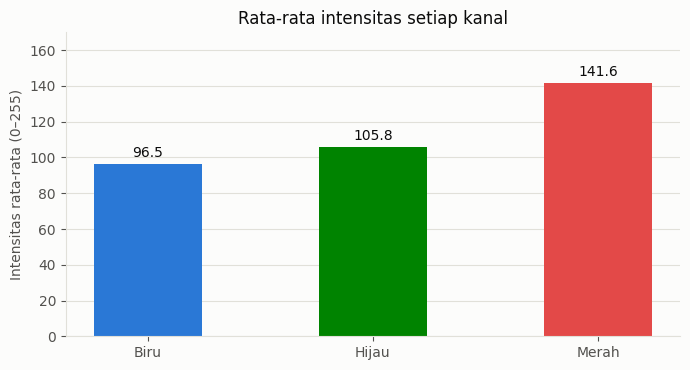

In [9]:
nama_kanal = ["Biru", "Hijau", "Merah"]
rata_kanal = [float(B.mean()), float(G.mean()), float(R.mean())]
warna_kanal = [BLUE, GREEN, RED]  # divalidasi; label langsung menjadi kanal kedua selain warna

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(nama_kanal, rata_kanal, color=warna_kanal, width=0.48)
ax.set_title("Rata-rata intensitas setiap kanal")
ax.set_ylabel("Intensitas rata-rata (0–255)")
ax.set_ylim(0, 170)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
for bar, nilai in zip(bars, rata_kanal):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 4,
            f"{nilai:.1f}", ha="center", color=INK)
fig.tight_layout()
fig.savefig(HASIL / "04_rata_rata_kanal.png", dpi=140, bbox_inches="tight")
plt.show()

**Interpretasi:** kanal merah memiliki rata-rata tertinggi pada citra astronaut, tetapi rata-rata global tidak berarti setiap piksel didominasi merah. Panel grayscale menunjukkan **besar nilai** kanal; panel berwarna menunjukkan **kontribusi warna** bila kanal lain dibuat nol.

Citra abu-abu hanya mempunyai satu kanal sehingga memori array-nya sepertiga citra warna. Namun, abu-abu bukan sekadar mengambil salah satu kanal; OpenCV menggabungkan B, G, dan R dengan bobot persepsi.

**Pertanyaan cepat:** mengapa berkas `kanal_merah.png` terlihat hitam putih ketika dibuka, meskipun berasal dari kanal merah?

### Langkah 4 — Memotong ROI dengan urutan indeks yang benar

Anggap detektor memberikan kotak `(x=180, y=60, w=180, h=200)`. Potongan benar menggunakan baris `y:y+h` lebih dahulu, lalu kolom `x:x+w`. Kita sengaja membuat potongan salah untuk melihat bug yang tetap menghasilkan array valid.

In [10]:
x, y, w_roi, h_roi = 180, 60, 180, 200
roi_view = img[y:y+h_roi, x:x+w_roi]           # benar, tetapi masih berbagi memori
roi = roi_view.copy()                           # salinan aman untuk dimodifikasi
roi_salah = img[x:x+w_roi, y:y+h_roi].copy()   # salah: x dan y tertukar

print("kotak detektor (x, y, w, h):", (x, y, w_roi, h_roi))
print("ROI benar :", roi.shape)
print("ROI salah :", roi_salah.shape)
print("roi_view berbagi memori dengan img:", np.shares_memory(img, roi_view))
print("roi hasil .copy() berbagi memori    :", np.shares_memory(img, roi))

cv2.imwrite(str(HASIL / "roi_benar.png"), roi)
cv2.imwrite(str(HASIL / "roi_salah.png"), roi_salah)

kotak detektor (x, y, w, h): (180, 60, 180, 200)
ROI benar : (200, 180, 3)
ROI salah : (180, 200, 3)
roi_view berbagi memori dengan img: True
roi hasil .copy() berbagi memori    : False


True

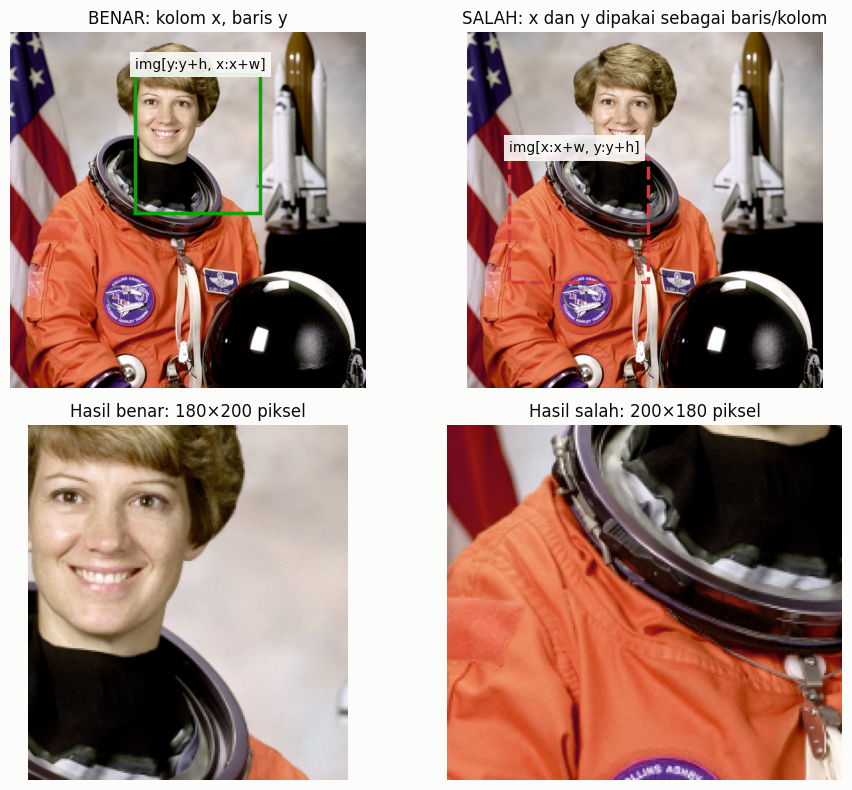

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

ax[0, 0].imshow(rgb_img)
ax[0, 0].add_patch(Rectangle((x, y), w_roi, h_roi, fill=False,
                             edgecolor="#0ca30c", linewidth=2.5))
ax[0, 0].set_title("BENAR: kolom x, baris y")
ax[0, 0].text(x, y-8, "img[y:y+h, x:x+w]", color=INK,
              bbox={"facecolor": SURFACE, "edgecolor": "none", "alpha": 0.9})

x_salah, y_salah = y, x
w_salah, h_salah = h_roi, w_roi
ax[0, 1].imshow(rgb_img)
ax[0, 1].add_patch(Rectangle((x_salah, y_salah), w_salah, h_salah, fill=False,
                             edgecolor="#d03b3b", linewidth=2.5, linestyle="--"))
ax[0, 1].set_title("SALAH: x dan y dipakai sebagai baris/kolom")
ax[0, 1].text(x_salah, y_salah-8, "img[x:x+w, y:y+h]", color=INK,
              bbox={"facecolor": SURFACE, "edgecolor": "none", "alpha": 0.9})

ax[1, 0].imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
ax[1, 0].set_title(f"Hasil benar: {roi.shape[1]}×{roi.shape[0]} piksel")
ax[1, 1].imshow(cv2.cvtColor(roi_salah, cv2.COLOR_BGR2RGB))
ax[1, 1].set_title(f"Hasil salah: {roi_salah.shape[1]}×{roi_salah.shape[0]} piksel")
for a in ax.ravel():
    a.axis("off")
fig.tight_layout()
fig.savefig(HASIL / "05_roi_benar_salah.png", dpi=140, bbox_inches="tight")
plt.show()

**Interpretasi:** kedua potongan memiliki ukuran masuk akal sehingga program tidak melempar galat. Kesalahan baru terlihat ketika lokasi kotak dan isi crop divisualisasikan. Inilah alasan visualisasi antara penting dalam pipeline visi komputer.

**Pertanyaan cepat:** apa yang terjadi pada `img` bila isi `roi_view` diubah menjadi nol? Mengapa hal yang sama tidak terjadi pada `roi`?

### Langkah 5 — Mengubah resolusi dan memetakan informasi yang hilang

Citra dikecilkan dari 512×512 menjadi 128×128, sehingga jumlah lokasi piksel tinggal `1/16`. Setelah dibesarkan kembali, bentuk array memang kembali 512×512, tetapi nilai piksel tidak sama dengan citra awal.

asli                 : (512, 512, 3) = 786,432 elemen
diperkecil           : (128, 128, 3) = 49,152 elemen
dibesarkan kembali   : (512, 512, 3)
galat absolut rata-rata (MAE): 7.95


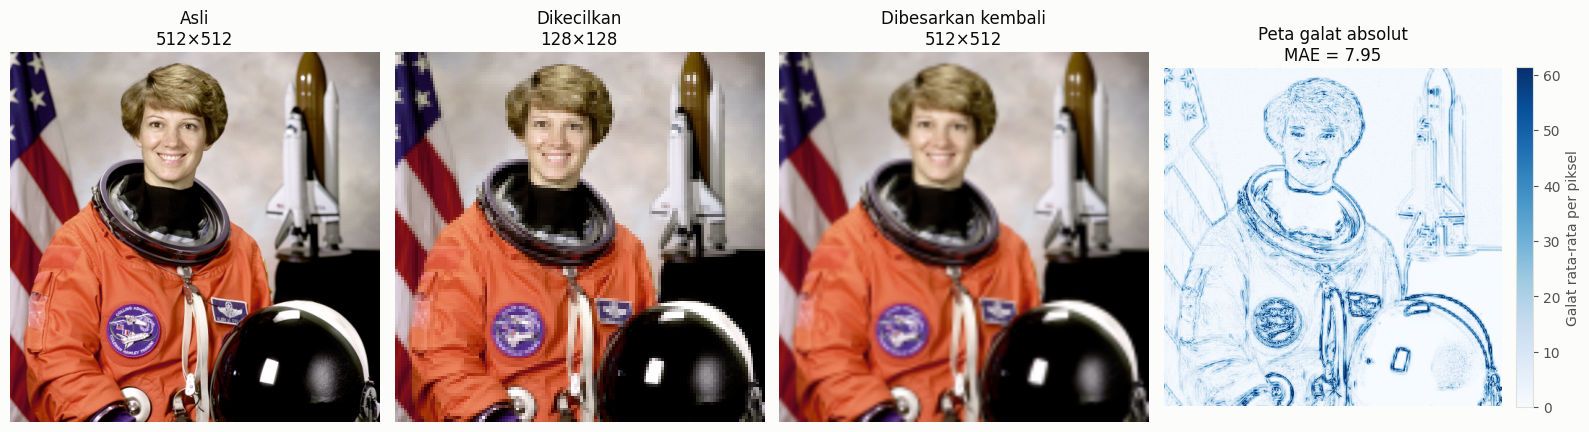

In [12]:
kecil = cv2.resize(img, (128, 128), interpolation=cv2.INTER_AREA)
besar = cv2.resize(kecil, (w, h), interpolation=cv2.INTER_LINEAR)
selisih_rgb = np.abs(img.astype(np.int16) - besar.astype(np.int16))
peta_galat = selisih_rgb.mean(axis=2)
mae_resize = float(selisih_rgb.mean())

print("asli                 :", img.shape, "=", f"{img.size:,}", "elemen")
print("diperkecil           :", kecil.shape, "=", f"{kecil.size:,}", "elemen")
print("dibesarkan kembali   :", besar.shape)
print("galat absolut rata-rata (MAE):", f"{mae_resize:.2f}")

fig, ax = plt.subplots(1, 4, figsize=(16, 4.2))
ax[0].imshow(rgb_img)
ax[0].set_title("Asli\n512×512")
ax[1].imshow(cv2.cvtColor(kecil, cv2.COLOR_BGR2RGB), interpolation="nearest")
ax[1].set_title("Dikecilkan\n128×128")
ax[2].imshow(cv2.cvtColor(besar, cv2.COLOR_BGR2RGB))
ax[2].set_title("Dibesarkan kembali\n512×512")
im = ax[3].imshow(peta_galat, cmap="Blues", vmin=0, vmax=max(30, float(np.percentile(peta_galat, 99))))
ax[3].set_title(f"Peta galat absolut\nMAE = {mae_resize:.2f}")
fig.colorbar(im, ax=ax[3], fraction=0.046, pad=0.04, label="Galat rata-rata per piksel")
for a in ax:
    a.axis("off")
fig.tight_layout()
fig.savefig(HASIL / "06_resize_dan_galat.png", dpi=140, bbox_inches="tight")
plt.show()

In [13]:
# Demo overflow uint8: hitung pada salinan agar citra utama tidak berubah.
nilai_uint8 = np.array([200], dtype=np.uint8)
nilai_uint8 += np.array([100], dtype=np.uint8)
nilai_int16 = np.int16(200) + np.int16(100)
nilai_aman = np.clip(nilai_int16, 0, 255).astype(np.uint8)

print("uint8:  200 + 100 ->", int(nilai_uint8[0]), "(meluber)")
print("int16:  200 + 100 ->", int(nilai_int16), "(nilai hitung sebenarnya)")
print("clip:   200 + 100 ->", int(nilai_aman), "(dibatasi ke rentang citra)")

uint8:  200 + 100 -> 44 (meluber)
int16:  200 + 100 -> 300 (nilai hitung sebenarnya)
clip:   200 + 100 -> 255 (dibatasi ke rentang citra)


**Interpretasi:** galat besar muncul terutama pada tepi dan detail halus. Interpolasi membuat transisi baru berdasarkan piksel yang tersisa, bukan memulihkan sampel yang telah dibuang. Peta galat menggunakan satu ramp biru: semakin gelap warnanya, semakin besar perbedaan terhadap citra asli.

Demo `uint8` menunjukkan alasan konversi tipe sebelum pengurangan. Tanpa `astype(np.int16)`, selisih dapat berputar di 0–255 dan menghasilkan metrik yang salah.

**Pertanyaan cepat:** mengapa `INTER_AREA` dipakai saat mengecilkan, sedangkan `INTER_LINEAR` dipakai saat membesarkan?

### Langkah 6 — Mengukur konsekuensi kompresi JPEG

Parameter kualitas JPEG berada pada rentang 0–100. Nilai tinggi mempertahankan lebih banyak informasi tetapi menghasilkan berkas lebih besar. Kita mengukur dua keluaran yang berbeda, sehingga keduanya digambar pada panel terpisah:

1. ukuran berkas dalam KiB;
2. galat absolut rata-rata (MAE) terhadap citra sebelum kompresi.

In [14]:
qualities = [95, 70, 30, 10]
hasil_jpeg = []
gambar_jpeg = {}

print(f"{'Kualitas':>8} | {'Ukuran (byte)':>13} | {'Ukuran (KiB)':>12} | {'MAE':>6}")
print("-" * 52)
for q in qualities:
    nama = HASIL / f"mutu_{q}.jpg"
    if not cv2.imwrite(str(nama), img, [int(cv2.IMWRITE_JPEG_QUALITY), q]):
        raise OSError(f"Gagal menyimpan {nama}")
    ulang = cv2.imread(str(nama), cv2.IMREAD_COLOR)
    if ulang is None:
        raise OSError(f"Gagal membaca kembali {nama}")
    ukuran = nama.stat().st_size
    mae = float(np.abs(img.astype(np.int16) - ulang.astype(np.int16)).mean())
    hasil_jpeg.append({"quality": q, "bytes": ukuran, "kib": ukuran/1024, "mae": mae})
    gambar_jpeg[q] = ulang
    print(f"{q:8d} | {ukuran:13,d} | {ukuran/1024:12.1f} | {mae:6.2f}")

Kualitas | Ukuran (byte) | Ukuran (KiB) |    MAE
----------------------------------------------------
      95 |        99,308 |         97.0 |   1.95
      70 |        36,800 |         35.9 |   3.42
      30 |        20,912 |         20.4 |   4.73
      10 |        11,564 |         11.3 |   7.73


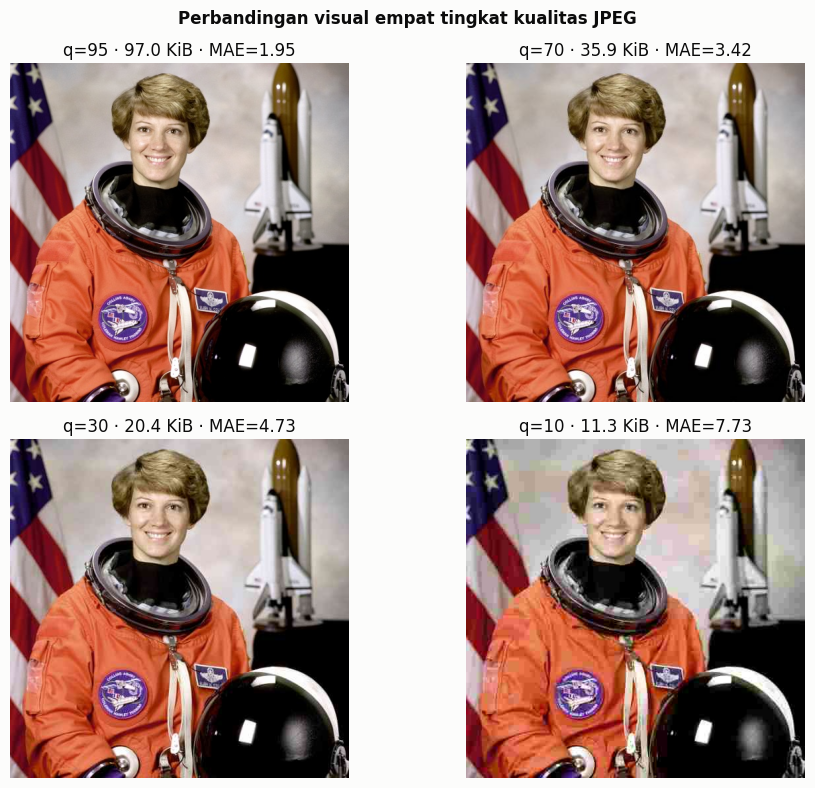

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
for a, hasil in zip(ax.ravel(), hasil_jpeg):
    q = hasil["quality"]
    a.imshow(cv2.cvtColor(gambar_jpeg[q], cv2.COLOR_BGR2RGB))
    a.set_title(f"q={q} · {hasil['kib']:.1f} KiB · MAE={hasil['mae']:.2f}")
    a.axis("off")
fig.suptitle("Perbandingan visual empat tingkat kualitas JPEG", weight="bold")
fig.tight_layout()
fig.savefig(HASIL / "07_montage_jpeg.png", dpi=140, bbox_inches="tight")
plt.show()

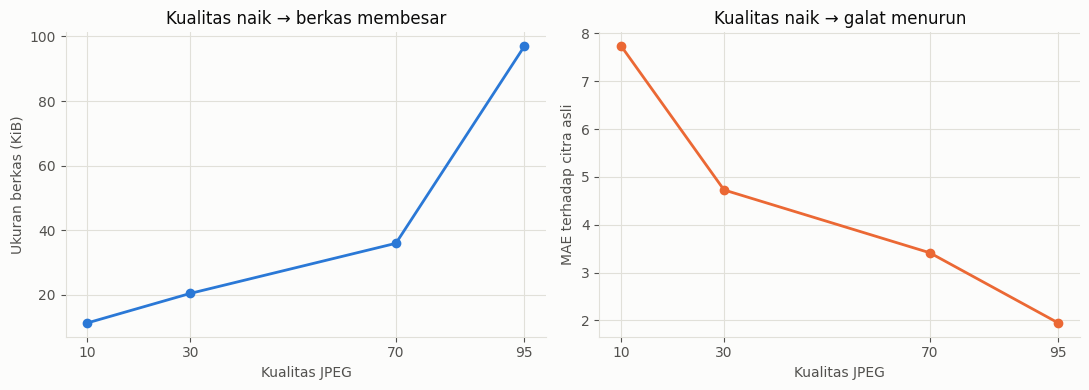

In [16]:
urut = sorted(hasil_jpeg, key=lambda d: d["quality"])
q_plot = [d["quality"] for d in urut]
size_plot = [d["kib"] for d in urut]
mae_plot = [d["mae"] for d in urut]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(q_plot, size_plot, color=BLUE, marker="o", linewidth=2)
ax[0].set_title("Kualitas naik → berkas membesar")
ax[0].set_xlabel("Kualitas JPEG")
ax[0].set_ylabel("Ukuran berkas (KiB)")

ax[1].plot(q_plot, mae_plot, color=ORANGE, marker="o", linewidth=2)
ax[1].set_title("Kualitas naik → galat menurun")
ax[1].set_xlabel("Kualitas JPEG")
ax[1].set_ylabel("MAE terhadap citra asli")

for a in ax:
    a.set_xticks(q_plot)
    a.grid(color=GRID, linewidth=0.8)
    a.set_axisbelow(True)
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(HASIL / "08_kurva_jpeg.png", dpi=140, bbox_inches="tight")
plt.show()

**Interpretasi:** kualitas 10 memberikan berkas paling kecil tetapi galat terbesar. Pada ukuran tampilan penuh, perbedaannya dapat tampak ringan; zoom pada wajah, tepi helm, dan area bertekstur memperlihatkan blok atau detail yang melebur. Tabel angka tetap diperlukan karena pengamatan visual dipengaruhi ukuran layar.

Ukuran berkas dan MAE tidak digabung pada satu sumbu ganda karena satuannya berbeda dan hubungan visualnya mudah menyesatkan. Dua panel mempertahankan skala yang jujur.

**Pertanyaan cepat:** bila citra akan dipakai sebagai data latih, apakah kualitas terkecil selalu pilihan terbaik karena hemat ruang? Jelaskan risiko terhadap fitur tepi dan tekstur.

## 5. Cek Pemahaman

Jawab sebelum melihat ulang kode.

1. Array berukuran `(1080, 1920, 3)` dengan `dtype=uint8` memerlukan berapa byte dan MiB di memori?
2. Apa perbedaan makna `img[100, 50]` dengan koordinat geometri `(100, 50)`?
3. Mengapa `plt.imshow(img)` menghasilkan warna keliru jika `img` berasal dari `cv2.imread`?
4. Apakah ukuran array berubah ketika citra disimpan sebagai JPEG kualitas 10 lalu dibaca kembali? Apa yang berubah?
5. Mengapa `.copy()` penting untuk ROI yang akan disensor, dicoret, atau dinormalisasi secara terpisah?
6. Jika citra 512×512 dikecilkan menjadi 128×128, berapa kali jumlah lokasi piksel berkurang?

<details>
<summary><strong>Kunci ringkas</strong></summary>

1. `1080×1920×3 = 6.220.800 byte ≈ 5,93 MiB`.
2. NumPy membaca `[baris=100, kolom=50]`, sedangkan `(x=100, y=50)` menunjuk kolom 100 dan baris 50.
3. OpenCV memberi BGR, Matplotlib menafsirkan tiga posisi sebagai RGB.
4. Bentuk array tetap sesuai dimensi citra; nilai piksel dan ukuran berkas berubah.
5. Slice biasanya berbagi memori dengan citra sumber.
6. `512² / 128² = 16` kali.

</details>

## 6. Eksperimen Mandiri

1. **Foto sendiri.** Ulangi Langkah 1–6 menggunakan `foto_saya.jpg`. Laporkan `shape`, `dtype`, `nbytes`, ukuran berkas asli, dan rasio memori mentah terhadap ukuran berkas.
2. **Piksel per objek.** Potong ROI berisi teks atau objek kecil. Ukur tingginya dalam piksel pada skala 100%, 50%, dan 25%. Tentukan skala pertama ketika objek tidak lagi mudah dikenali dan sertakan tiga visual berdampingan.
3. **Kanal dominan bergantung objek.** Ganti citra dengan `skimage.data.coffee()`. Tampilkan tiga kanal grayscale dan grafik rata-ratanya. Tentukan kanal yang paling memperjelas batas cangkir terhadap meja menggunakan bukti visual dan angka.
4. **Kompromi JPEG.** Tambahkan kualitas 50. Bandingkan ukuran, MAE, dan tampilan ROI bertekstur. Pilih kualitas yang menurutmu memberi kompromi terbaik untuk penyimpanan dataset dan jelaskan kriterianya.

> Untuk setiap eksperimen, sertakan angka pengukuran dan visual. Pernyataan “terlihat lebih baik” tanpa lokasi, skala, atau metrik belum cukup.

## 7. Tugas dan Format Laporan

Kumpulkan `VK_P01_<NIM>_<Nama>.pdf` dan kode/notebook dalam `VK_P01_<NIM>.zip` sebelum sesi berikutnya. Laporan memuat:

1. tabel struktur citra (`shape`, `dtype`, jumlah elemen, `nbytes`, ukuran berkas, rasio);
2. visual BGR versus RGB beserta penjelasan urutan kanal;
3. visual kanal, rata-rata tiap kanal, dan interpretasi objek/warna dominan;
4. ROI benar versus salah serta penjelasan `[y, x]`;
5. hasil resize dan peta galat beserta MAE;
6. tabel serta kurva JPEG, lalu rekomendasi kualitas berdasarkan angka dan visual;
7. hasil minimal tiga eksperimen mandiri.

## 8. Rubrik Penilaian

| Kriteria | Bobot | Sangat Kurang (0) | Cukup (50–65) | Baik (80) | Sangat Baik (95–100) |
|---|---:|---|---|---|---|
| Kode dan reproduksibilitas | 25% | Tidak berjalan | Sebagian langkah berjalan | Enam langkah berjalan berurutan | Berjalan, rapi, dan semua keluaran dapat direproduksi |
| Representasi dan koordinat | 25% | Tidak dijelaskan | Menyebut shape/BGR | Menghubungkan HWC, BGR/RGB, dan `[y, x]` | Ditambah analisis view vs copy dan contoh bug ROI |
| Pengukuran kehilangan informasi | 30% | Tanpa angka | Hanya ukuran atau MAE | Resize dan JPEG disertai metrik | Metrik, visual, dan mekanisme kehilangan dijelaskan |
| Eksperimen dan kesimpulan | 20% | Tidak ada | Satu eksperimen | Tiga eksperimen dengan angka | Eksperimen lengkap dan rekomendasi berbasis bukti |

## 9. Kesalahan Umum dan Cara Mengatasinya

1. **`AttributeError: 'NoneType' object has no attribute 'shape'`**
   `cv2.imread` gagal. Periksa `Path(nama).exists()`, direktori kerja, ekstensi, dan izin baca; selalu uji `img is None`.
2. **Warna kebiruan di Matplotlib**
   Array masih BGR. Gunakan `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` sebelum `imshow`.
3. **ROI berukuran masuk akal tetapi salah lokasi**
   Urutan indeks tertukar. Ingat: kotak `(x, y, w, h)`, slice `[y:y+h, x:x+w]`.
4. **Mengubah ROI ikut mengubah citra sumber**
   Slice adalah *view*. Tambahkan `.copy()` jika ROI perlu diedit mandiri.
5. **Selisih/penjumlahan menghasilkan pola aneh**
   Terjadi overflow `uint8`. Konversi ke `int16` atau `float32`, hitung, lalu `np.clip` bila kembali ke citra 8-bit.
6. **`cv2.resize` memberi bentuk terbalik**
   Argumen ukuran adalah `(lebar, tinggi)`, bukan urutan `shape` `(tinggi, lebar)`.
7. **`cv2.imwrite` tidak menghasilkan berkas yang diharapkan**
   Periksa nilai kembalian Boolean dan pastikan folder tujuan ada.
8. **Kualitas JPEG dibandingkan dari dimensi gambar saja**
   Dimensi dapat sama walau nilai piksel berbeda. Gunakan ukuran berkas, MAE, dan crop visual yang sama.

## 10. Ringkasan

- Kamera menghasilkan sampel spasial yang dikuantisasi menjadi angka.
- Citra warna OpenCV adalah array `(H, W, 3)` bertipe `uint8` dengan urutan BGR.
- Ukuran memori ditentukan oleh dimensi dan tipe data; ukuran berkas ditentukan pula oleh metode kompresi.
- Koordinat geometri `(x, y)` diterapkan pada NumPy sebagai `[y, x]`.
- Memisahkan kanal, memotong ROI, dan mengubah resolusi adalah operasi array yang harus selalu diverifikasi secara visual.
- Resize dan JPEG dapat mempertahankan dimensi tampilan tetapi tetap membuang informasi; kehilangan itu dapat diukur dengan MAE.

In [ ]:
# Self-check minimum: sel ini harus lulus setelah semua langkah dijalankan berurutan.
assert img.shape == (512, 512, 3) and img.dtype == np.uint8
assert img.size == h * w * c == img.nbytes
assert roi.shape == (h_roi, w_roi, 3)
assert kecil.shape == (128, 128, 3) and besar.shape == img.shape
assert len(hasil_jpeg) == 4
assert all(np.isfinite(d["mae"]) and d["bytes"] > 0 for d in hasil_jpeg)
assert hasil_jpeg[0]["bytes"] > hasil_jpeg[-1]["bytes"]
assert hasil_jpeg[0]["mae"] < hasil_jpeg[-1]["mae"]
print("✓ Self-check lulus: struktur, ROI, resize, dan tren JPEG konsisten.")